<a href="https://colab.research.google.com/github/prof-atritiack/CHECKPOINT_02_SERS_1CC_2SEM/blob/main/Aula_APIs_Energia_Renovavel_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avaliação — APIs de energia renovável e aprendizado de máquina

Consulte duas APIs públicas, organize os dados e resolva **duas tarefas**: classificar a fonte de empreendimentos da ANEEL e estimar a radiação solar em Petrolina (PE). Em **cada tarefa**, treine e compare **três algoritmos diferentes**. Este notebook fornece a consulta às APIs e os arquivos de dados; **você implementará a análise e os modelos**.

**Entrega:** um único link para um repositório público no GitHub com notebook executável, arquivos de dados, README e resultados. As instruções completas estão ao final e no enunciado separado.

## O que é recebido da API?

Uma requisição HTTP `GET` pede dados a uma URL. Os parâmetros identificam o recurso, o período e as variáveis. A resposta é **JSON**: um objeto com chaves e valores. Nas duas consultas desta avaliação, o acesso público **não exige login, token ou chave de API**. Se outra API exigir credenciais, não as publique no repositório.

Este código usa somente `json`, `urllib` e `csv`, bibliotecas que vêm com Python. `csv` serve apenas para exportar os dados recebidos; os imports para análise, tabelas, gráficos e ML são parte da sua implementação.

In [1]:
import json
import urllib.parse
import urllib.request
import csv

A função a seguir monta a URL, abre a conexão, verifica o status HTTP e converte o JSON. Se houver falha na rede ou na API, exibe uma mensagem de erro.

In [2]:
def consultar_api(endereco, parametros):
    url = endereco + "?" + urllib.parse.urlencode(parametros)
    try:
        with urllib.request.urlopen(url, timeout=100) as resposta:
            return json.load(resposta)
    except Exception as erro:
        raise RuntimeError(f"Não foi possível consultar a API: {erro}") from erro

# Tarefa 1 — Classificação (ANEEL)

**Pergunta:** a partir da potência e da localização de um empreendimento, é possível classificar sua fonte como **Solar, Eólica ou Hidráulica**?

A fonte é uma **categoria**: o problema é de classificação. O conjunto [SIGA da ANEEL](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel) registra empreendimentos em várias fases. Usamos `UFV` (solar fotovoltaica), `EOL` (eólica) e três categorias hidráulicas: `UHE`, `PCH`, `CGH`. Estas três últimas formarão uma única classe, *Hidráulica*. A tarefa trata da **categoria do cadastro**, não da quantidade de energia gerada.

### Atributos originais da resposta

| Campo da API | Significado | Uso na tarefa |
|---|---|---|
| `SigTipoGeracao` | Sigla do tipo de geração (`UFV`, `EOL`, `UHE`, `PCH`, `CGH`) | Origina o alvo `fonte`; **não entra em X** |
| `MdaPotenciaOutorgadaKw` | Potência outorgada do empreendimento, em quilowatts (kW) | Entrada `potencia_kw`; potência nominal autorizada, não energia produzida |
| `NumCoordNEmpreendimento` | Latitude aproximada do empreendimento, em graus decimais | Entrada `latitude` |
| `NumCoordEEmpreendimento` | Longitude aproximada do empreendimento, em graus decimais | Entrada `longitude` |
| `CodCEG`, `NomEmpreendimento` e campos de combustível | Código, nome e descrição associados ao empreendimento e à fonte | **Não usar como entradas**: podem revelar a classe |

A resposta CKAN contém `success` e `result`; dentro de `result`, `records` são as linhas, `fields` descrevem as colunas e `total` indica o total encontrado para o filtro. O CSV final terá **três atributos numéricos e a classe**. Quantidades consultadas têm limite por tipo e não representam a participação de cada fonte na matriz brasileira.

### 1. Consultar a ANEEL

O recurso SIGA é acessado pela API pública CKAN/DataStore. `resource_id` aponta para o conjunto; `filters` seleciona uma sigla; `limit` limita o retorno de cada pedido. Não há etapa de autenticação para esta consulta pública.

In [3]:
URL_ANEEL = "https://dadosabertos.aneel.gov.br/api/3/action/datastore_search"
ID_RECURSO = "11ec447d-698d-4ab8-977f-b424d5deee6a"
SIGLAS = ["UFV", "EOL", "UHE", "PCH", "CGH"]
URL_COPIA_CSV = "https://raw.githubusercontent.com/prof-atritiack/CHECKPOINT_02_SERS_1CC_2SEM/refs/heads/main/"
print("API ANEEL: consulta pública, sem token")

API ANEEL: consulta pública, sem token


In [4]:
registros_aneel = []
try:
    for sigla in SIGLAS:
        parametros = {
            "resource_id": ID_RECURSO,
            "filters": json.dumps({"SigTipoGeracao": sigla}),
            "limit": 1200,
        }
        resposta = consultar_api(URL_ANEEL, parametros)
        if not resposta.get("success"):
            raise ValueError(f"Consulta da ANEEL falhou para {sigla}")
        linhas = resposta["result"]["records"]
        print(f"{sigla}: {len(linhas)} linhas recebidas")
        registros_aneel.extend(linhas)
    print("Total de linhas recebidas:", len(registros_aneel))
except (RuntimeError, ValueError) as erro:
    registros_aneel = []
    print("API da ANEEL indisponível neste ambiente:", erro)
    print("Será usada a cópia publicada do CSV gerado por este mesmo código.")

API da ANEEL indisponível neste ambiente: Não foi possível consultar a API: <urlopen error Tunnel connection failed: 403 Forbidden>
Será usada a cópia publicada do CSV gerado por este mesmo código.


### 2. Gerar o CSV para a tarefa

A API pode fornecer números como texto, inclusive com vírgula decimal. O tratamento abaixo converte esses valores, descarta linhas sem potência ou coordenadas e transforma as siglas em três classes. Cada linha do arquivo final representa **um empreendimento**. Confira a quantidade de exemplos por classe durante sua análise; se necessário, discuta o desequilíbrio entre classes.

In [5]:
def numero(valor):
    texto = str(valor).strip()
    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")
    try:
        return float(texto)
    except ValueError:
        return None

fontes = {"UFV": "Solar", "EOL": "Eólica", "UHE": "Hidráulica",
          "PCH": "Hidráulica", "CGH": "Hidráulica"}
linhas_classificacao = []
for registro in registros_aneel:
    potencia = numero(registro.get("MdaPotenciaOutorgadaKw"))
    latitude = numero(registro.get("NumCoordNEmpreendimento"))
    longitude = numero(registro.get("NumCoordEEmpreendimento"))
    fonte = fontes.get(registro.get("SigTipoGeracao"))
    if fonte and all(valor is not None for valor in (potencia, latitude, longitude)):
        linhas_classificacao.append([potencia, latitude, longitude, fonte])
if registros_aneel:
    if len(linhas_classificacao) < 90:
        raise ValueError("Poucos registros válidos: confira a resposta da ANEEL")
    print("Linhas válidas:", len(linhas_classificacao))
    print("Primeiro exemplo:", linhas_classificacao[0])

In [6]:
if linhas_classificacao:
    with open("aneel_classificacao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
        escritor = csv.writer(arquivo)
        escritor.writerow(["potencia_kw", "latitude", "longitude", "fonte"])
        escritor.writerows(linhas_classificacao)
else:
    urllib.request.urlretrieve(URL_COPIA_CSV + "aneel_classificacao_orange.csv", "aneel_classificacao_orange.csv")
print("Salvo: aneel_classificacao_orange.csv")

Salvo: aneel_classificacao_orange.csv


### O que você deve fazer — classificação

1. Carregue o CSV, confira os tipos das colunas, as contagens por classe, valores ausentes e distribuições relevantes. Explique `X` (três entradas) e `y` (`fonte`).
2. Faça uma divisão **estratificada** de treino/teste, por exemplo 80%/20%, com semente fixa. Ajustes de escala aprendidos dos dados devem ser feitos **somente com o treino**.
3. Escolha, justifique e treine **três classificadores diferentes** usando a mesma divisão. Eles **não estão importados nem implementados** neste notebook.
4. Compare Accuracy, Precision, Recall e F1. Declare o tipo de média usado nas métricas por classe (por exemplo, `macro`) e apresente a matriz de confusão.
5. Explique qual modelo escolheria, quais classes ele mais confunde e por que potência/localização podem não bastar para uma aplicação real. Não use `SigTipoGeracao`, nomes, CEG ou descrições da fonte como entradas.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico(s) ou matriz de confusão e interpretação escrita.

## Resolução — Tarefa 1 (classificação)

### 5. Bibliotecas e configuração

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

SEMENTE = 42
CLASSES = ["Eólica", "Hidráulica", "Solar"]
CORES = {"Eólica": "#2a9d8f", "Hidráulica": "#264653", "Solar": "#e9c46a"}
plt.rcParams["figure.dpi"] = 100

### 6. Exploração dos dados da ANEEL

In [8]:
dados = pd.read_csv("aneel_classificacao_orange.csv", encoding="utf-8-sig")
print("Linhas:", dados.shape[0], "| Colunas:", dados.shape[1])
print()
print(dados.dtypes)
dados.head()

Linhas: 3876 | Colunas: 4

potencia_kw    float64
latitude       float64
longitude      float64
fonte              str
dtype: object


,potencia_kw,latitude,longitude,fonte
0,20.48,-10.442778,-64.151944,Solar
1,5000.00,-6.003889,-40.274722,Solar
2,12.26,-23.557778,-46.734000,Solar
3,3.00,-23.558889,-46.735000,Solar
4,1.70,-23.493819,-46.845000,Solar


In [9]:
print("Valores ausentes por coluna:")
print(dados.isna().sum())
print()
print("Linhas totalmente duplicadas:", dados.duplicated().sum())
coordenada_nula = (dados["latitude"] == 0) & (dados["longitude"] == 0)
print("Linhas com coordenada (0, 0):", coordenada_nula.sum())
print(dados.loc[coordenada_nula, "fonte"].value_counts().to_string())

Valores ausentes por coluna:
potencia_kw    0
latitude       0
longitude      0
fonte          0
dtype: int64

Linhas totalmente duplicadas: 28
Linhas com coordenada (0, 0): 47
fonte
Eólica        24
Hidráulica    23


In [10]:
contagem = dados["fonte"].value_counts()
distribuicao = pd.DataFrame({"exemplos": contagem,
                             "proporção (%)": (100 * contagem / len(dados)).round(1)})
distribuicao

,exemplos,proporção (%)
fonte,,
Hidráulica,1476,38.1
Solar,1200,31.0
Eólica,1200,31.0


In [11]:
dados.groupby("fonte")["potencia_kw"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
fonte,,,,,,,,
Eólica,1200.0,30782.8,13800.6,0.2,23100.0,29600.0,37200.0,105000.0
Hidráulica,1476.0,75809.2,486419.6,1.0,990.0,4000.0,17000.0,11233100.0
Solar,1200.0,11679.4,18374.9,0.3,1.0,1.0,28880.0,137480.0


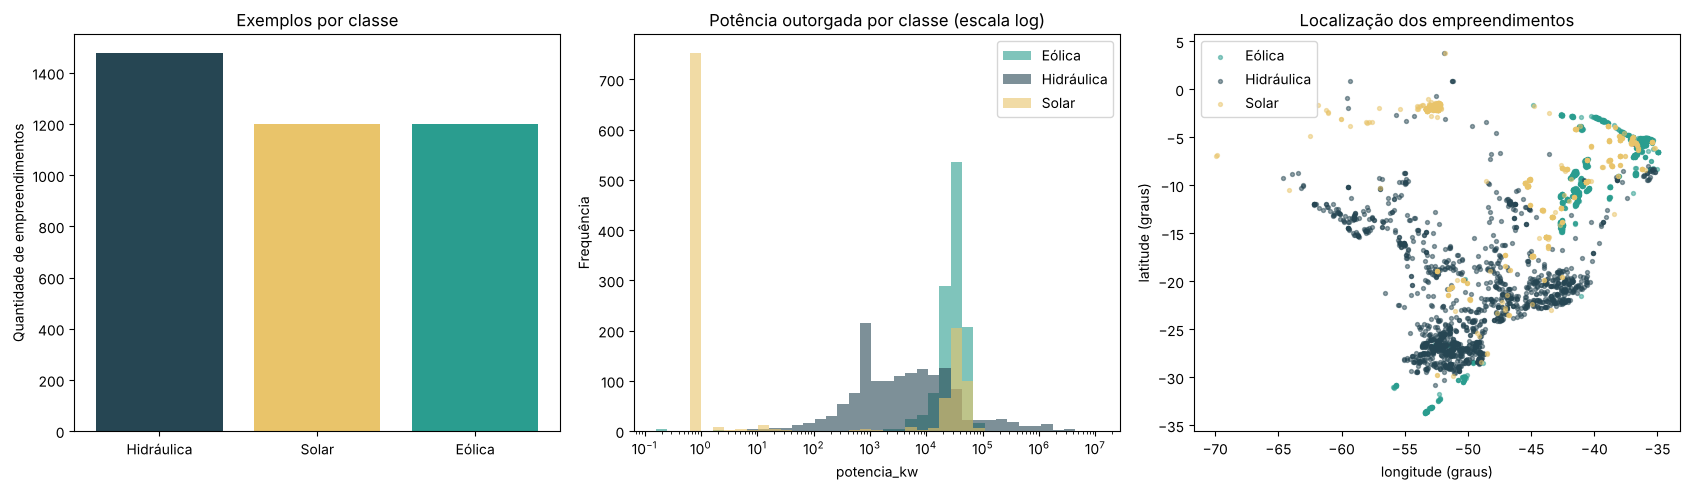

In [12]:
validos = dados[~coordenada_nula]
fig, eixos = plt.subplots(1, 3, figsize=(17, 5))

eixos[0].bar(contagem.index, contagem.values, color=[CORES[c] for c in contagem.index])
eixos[0].set_title("Exemplos por classe")
eixos[0].set_ylabel("Quantidade de empreendimentos")

faixas = np.logspace(np.log10(dados["potencia_kw"].min()), np.log10(dados["potencia_kw"].max()), 40)
for classe in CLASSES:
    eixos[1].hist(dados.loc[dados["fonte"] == classe, "potencia_kw"], bins=faixas,
                  alpha=0.6, label=classe, color=CORES[classe])
eixos[1].set_xscale("log")
eixos[1].set_title("Potência outorgada por classe (escala log)")
eixos[1].set_xlabel("potencia_kw")
eixos[1].set_ylabel("Frequência")
eixos[1].legend()

for classe in CLASSES:
    parte = validos[validos["fonte"] == classe]
    eixos[2].scatter(parte["longitude"], parte["latitude"], s=8, alpha=0.5,
                     label=classe, color=CORES[classe])
eixos[2].set_title("Localização dos empreendimentos")
eixos[2].set_xlabel("longitude (graus)")
eixos[2].set_ylabel("latitude (graus)")
eixos[2].legend()
plt.tight_layout()
plt.show()

**O que a exploração mostra**

- O arquivo tem **3.876 empreendimentos** e **nenhum valor ausente**. As três entradas são numéricas (`float64`) e o alvo `fonte` é categórico.
- **Distribuição das classes:** Hidráulica 1.476 (38,1%), Solar 1.200 (31,0%) e Eólica 1.200 (31,0%). O desequilíbrio é pequeno, mas existe; por isso a divisão é estratificada e as métricas usam média `macro`. Essas quantidades vêm do **limite de 1.200 registros por sigla** usado na consulta (a classe Hidráulica soma UHE, PCH e CGH) e **não representam a participação das fontes na matriz energética brasileira**.
- **Potência:** a escala é extremamente assimétrica (de 0,16 kW a mais de 11 milhões de kW), por isso o histograma usa escala logarítmica. Mais de 750 registros solares têm potência de exatamente **1 kW**, um valor que funciona quase como uma "assinatura" da classe neste recorte. As eólicas concentram-se entre ~20 e 40 MW (potência típica de um parque), enquanto as hidráulicas variam de pequenas CGHs a grandes UHEs.
- **Localização:** eólicas estão concentradas no litoral do Nordeste e no Rio Grande do Sul; hidráulicas espalham-se pelo Sul, Sudeste e Centro-Oeste; solares aparecem em aglomerados no Nordeste, em Minas Gerais e em São Paulo. Há sobreposição espacial entre classes, principalmente no Nordeste.
- **Problemas de qualidade:** 47 linhas têm coordenada **(0, 0)**, ponto no Oceano Atlântico que indica coordenada não informada. Elas serão removidas, pois a localização é uma das entradas. Há também 28 linhas totalmente duplicadas, que foram mantidas porque podem ser unidades distintas de um mesmo complexo com mesma potência e coordenada aproximada.

### 7. Limpeza, definição de X e y e divisão estratificada

In [13]:
dados = dados[~coordenada_nula].reset_index(drop=True)
print("Linhas após remover coordenadas (0, 0):", len(dados))

ATRIBUTOS_CLASS = ["potencia_kw", "latitude", "longitude"]
X = dados[ATRIBUTOS_CLASS]
y = dados["fonte"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE)

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
pd.DataFrame({"treino (%)": (100 * y_treino.value_counts(normalize=True)).round(1),
              "teste (%)": (100 * y_teste.value_counts(normalize=True)).round(1)})

Linhas após remover coordenadas (0, 0): 3829
Treino: (3063, 3) | Teste: (766, 3)


,treino (%),teste (%)
fonte,,
Hidráulica,37.9,38.0
Solar,31.3,31.3
Eólica,30.7,30.7


### Escolha dos três classificadores

| Algoritmo | Por que foi escolhido | Pré-processamento |
|---|---|---|
| **Regressão Logística** | Modelo linear e interpretável; serve como linha de base e mostra até onde fronteiras lineares separam as classes. | `log10(potencia_kw)` + padronização (`StandardScaler`) |
| **kNN (k = 5)** | Classifica pelo voto dos vizinhos mais próximos; é natural para dados geográficos, em que empreendimentos próximos tendem a ser da mesma fonte. | `log10(potencia_kw)` + padronização (`StandardScaler`) |
| **Random Forest (300 árvores)** | Conjunto de árvores que captura relações não lineares e interações (ex.: "potência ~30 MW **e** litoral do Nordeste"), sem exigir escala. | Nenhum |

A transformação logarítmica é aplicada porque a potência varia em várias ordens de grandeza. A padronização fica **dentro de um `Pipeline`**, então média e desvio são aprendidos **somente com o treino** e depois aplicados ao teste. Nomes, código CEG, siglas e descrições **não** são usados como entrada.

In [14]:
def log_potencia(tabela):
    tabela = tabela.copy()
    tabela["potencia_kw"] = np.log10(tabela["potencia_kw"])
    return tabela

classificadores = {
    "Regressão Logística": make_pipeline(FunctionTransformer(log_potencia), StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
    "kNN (k=5)": make_pipeline(FunctionTransformer(log_potencia), StandardScaler(),
                               KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEMENTE),
}

### 8. Treinamento e comparação dos três classificadores

Todos usam **a mesma divisão** (80% treino / 20% teste, estratificada, `random_state=42`). Precision, Recall e F1 usam **média `macro`**: a métrica é calculada por classe e depois feita a média simples, dando o mesmo peso a Solar, Eólica e Hidráulica.

In [15]:
previsoes_class = {}
linhas = []
for nome, modelo in classificadores.items():
    modelo.fit(X_treino, y_treino)
    previsao = modelo.predict(X_teste)
    previsoes_class[nome] = previsao
    linhas.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_teste, previsao),
        "Precision (macro)": precision_score(y_teste, previsao, average="macro"),
        "Recall (macro)": recall_score(y_teste, previsao, average="macro"),
        "F1 (macro)": f1_score(y_teste, previsao, average="macro"),
    })

resultados_class = pd.DataFrame(linhas).set_index("Modelo").sort_values("F1 (macro)", ascending=False)
resultados_class.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Modelo,,,,
Random Forest,0.9765,0.9774,0.9759,0.9765
kNN (k=5),0.9648,0.9652,0.9642,0.9647
Regressão Logística,0.8316,0.8469,0.8282,0.8251


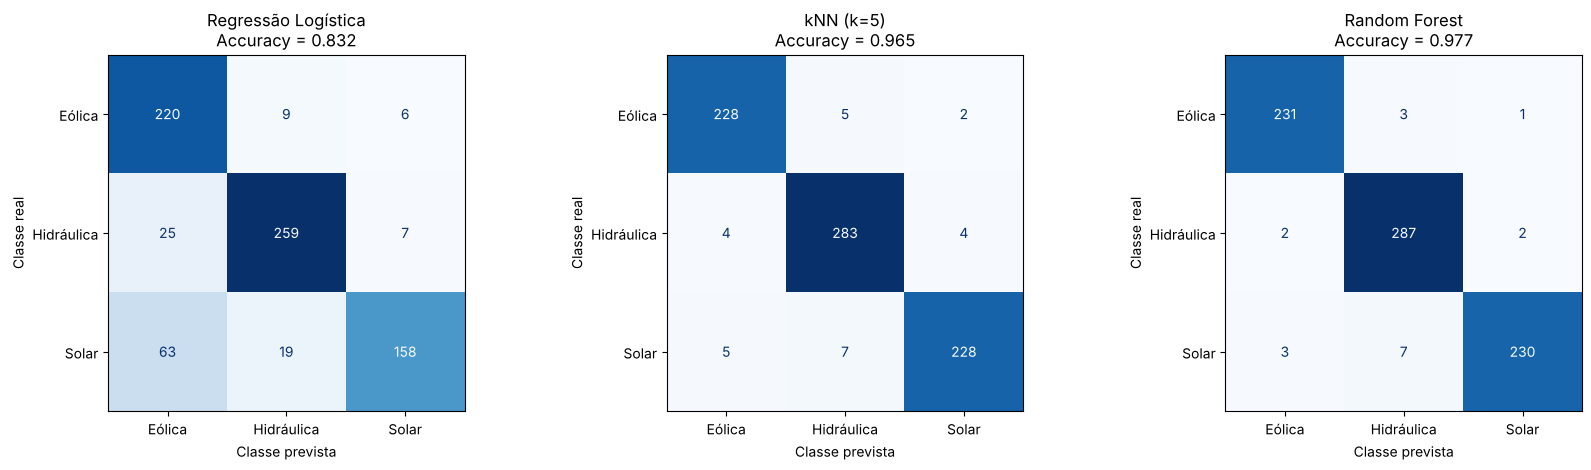

In [16]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8))
for eixo, (nome, previsao) in zip(eixos, previsoes_class.items()):
    matriz = confusion_matrix(y_teste, previsao, labels=CLASSES)
    ConfusionMatrixDisplay(matriz, display_labels=CLASSES).plot(ax=eixo, cmap="Blues", colorbar=False)
    eixo.set_title(f"{nome}\nAccuracy = {accuracy_score(y_teste, previsao):.3f}")
    eixo.set_xlabel("Classe prevista")
    eixo.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

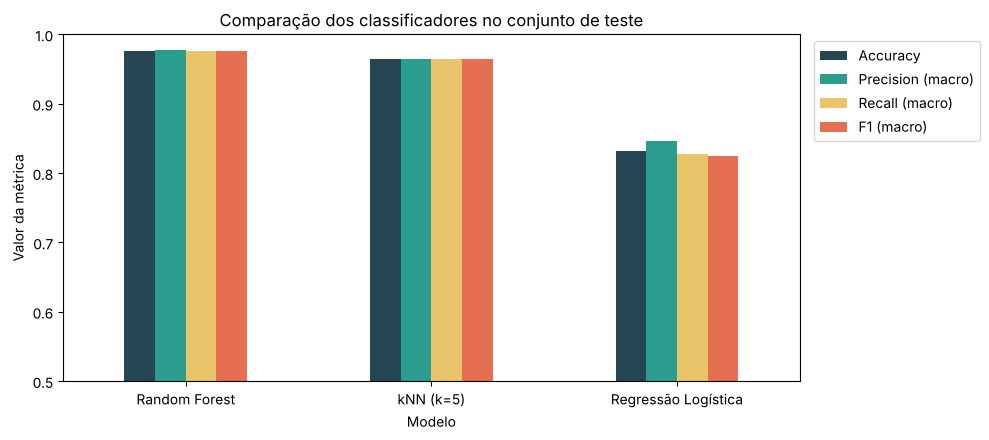

In [17]:
resultados_class[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot.bar(
    figsize=(10, 4.5), rot=0, ylim=(0.5, 1.0), color=["#264653", "#2a9d8f", "#e9c46a", "#e76f51"])
plt.title("Comparação dos classificadores no conjunto de teste")
plt.ylabel("Valor da métrica")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [18]:
melhor_class = resultados_class.index[0]
print("Melhor modelo pelo F1 macro:", melhor_class)
print()
print(classification_report(y_teste, previsoes_class[melhor_class], digits=3))

Melhor modelo pelo F1 macro: Random Forest

              precision    recall  f1-score   support

      Eólica      0.979     0.983     0.981       235
  Hidráulica      0.966     0.986     0.976       291
       Solar      0.987     0.958     0.973       240

    accuracy                          0.977       766
   macro avg      0.977     0.976     0.977       766
weighted avg      0.977     0.977     0.976       766



In [19]:
confusoes = []
for nome, previsao in previsoes_class.items():
    matriz = pd.DataFrame(confusion_matrix(y_teste, previsao, labels=CLASSES), index=CLASSES, columns=CLASSES)
    for real in CLASSES:
        for prevista in CLASSES:
            if real != prevista:
                confusoes.append({"Modelo": nome, "Real": real, "Prevista": prevista, "Erros": matriz.loc[real, prevista]})
tabela_confusoes = pd.DataFrame(confusoes).pivot_table(index=["Real", "Prevista"], columns="Modelo", values="Erros")
tabela_confusoes

Modelo                 Random Forest  Regressão Logística  kNN (k=5)
Real       Prevista                                                 
Eólica     Hidráulica            3.0                  9.0        5.0
           Solar                 1.0                  6.0        2.0
Hidráulica Eólica                2.0                 25.0        4.0
           Solar                 2.0                  7.0        4.0
Solar      Eólica                3.0                 63.0        5.0
           Hidráulica            7.0                 19.0        7.0

### 9. Verificação da robustez

Para confirmar que a ordem dos modelos não depende de uma única divisão, os três foram avaliados também com **validação cruzada estratificada de 5 partes apenas no conjunto de treino** (o teste continua intocado).

In [20]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for nome, modelo in classificadores.items():
    notas = cross_validate(modelo, X_treino, y_treino, cv=validacao, scoring=["accuracy", "f1_macro"])
    linhas.append({"Modelo": nome,
                   "Accuracy média": notas["test_accuracy"].mean(),
                   "Accuracy desvio": notas["test_accuracy"].std(),
                   "F1 macro média": notas["test_f1_macro"].mean(),
                   "F1 macro desvio": notas["test_f1_macro"].std()})
pd.DataFrame(linhas).set_index("Modelo").round(4)

,Accuracy média,Accuracy desvio,F1 macro média,F1 macro desvio
Modelo,,,,
Regressão Logística,0.8067,0.0115,0.8007,0.0120
kNN (k=5),0.9576,0.0082,0.9565,0.0083
Random Forest,0.9716,0.0045,0.9710,0.0047


A acurácia muito alta de kNN e Random Forest levantou uma suspeita: empreendimentos de um mesmo complexo (parques eólicos com várias usinas, usinas solares divididas em blocos) costumam ter coordenadas quase iguais e potências parecidas. A célula abaixo mede quantos exemplos de teste têm um "vizinho" no treino a menos de 0,01° (cerca de 1 km) e compara o acerto do melhor modelo nos dois grupos.

In [21]:
coord_treino = np.radians(X_treino[["latitude", "longitude"]].to_numpy())
coord_teste = np.radians(X_teste[["latitude", "longitude"]].to_numpy())
distancias = np.full(len(coord_teste), np.inf)
for inicio in range(0, len(coord_teste), 200):
    bloco = coord_teste[inicio:inicio + 200]
    diferenca = np.sqrt(((bloco[:, None, :] - coord_treino[None, :, :]) ** 2).sum(axis=2))
    distancias[inicio:inicio + 200] = np.degrees(diferenca.min(axis=1))

tem_vizinho = distancias < 0.01
acertos = previsoes_class[melhor_class] == y_teste.to_numpy()
pd.DataFrame({
    "Exemplos de teste": [tem_vizinho.sum(), (~tem_vizinho).sum()],
    "Proporção (%)": [100 * tem_vizinho.mean(), 100 * (~tem_vizinho).mean()],
    f"Accuracy ({melhor_class})": [acertos[tem_vizinho].mean(), acertos[~tem_vizinho].mean()],
}, index=["Com vizinho no treino (< 0,01°)", "Sem vizinho próximo"]).round(3)

,Exemplos de teste,Proporção (%),Accuracy (Random Forest)
"Com vizinho no treino (< 0,01°)",247,32.245,0.984
Sem vizinho próximo,519,67.755,0.973


### 10. Interpretação — classificação

**Tabela comparativa (teste, 766 empreendimentos; Precision/Recall/F1 com média `macro`):**

| Modelo | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Random Forest | 0,977 | 0,977 | 0,976 | 0,977 |
| kNN (k = 5) | 0,965 | 0,965 | 0,964 | 0,965 |
| Regressão Logística | 0,832 | 0,847 | 0,828 | 0,825 |

- **Modelo escolhido: Random Forest.** Teve os melhores valores em todas as métricas e a mesma ordem se repetiu na validação cruzada de 5 partes no treino (F1 macro 0,971 ± 0,005), com a menor variação entre partes. O kNN fica muito próximo; a Regressão Logística é claramente inferior.
- **Classes mais confundidas:**
  - Na **Regressão Logística**, o maior erro é **Solar prevista como Eólica** (63 casos) e, em seguida, **Hidráulica prevista como Eólica** (25). Fronteiras lineares não conseguem separar bem regiões que se intercalam no mapa (ex.: solares e eólicas no Nordeste) nem a faixa de potência em que as três classes se sobrepõem (10 a 100 MW).
  - No **Random Forest** e no **kNN**, os poucos erros concentram-se em **Solar prevista como Hidráulica** (7 casos em cada) — usinas solares de médio porte localizadas em regiões dominadas por hidrelétricas (Sudeste/Centro-Oeste) — e em **Eólica ↔ Hidráulica**.
- **Por que o acerto é tão alto e por que isso não garante uso real:**
  - Cerca de **32% dos empreendimentos de teste têm outro empreendimento do treino a menos de ~1 km**. Muitos registros pertencem ao mesmo complexo (parques eólicos com várias usinas, usinas solares divididas em blocos) e a divisão aleatória coloca "irmãos" no treino e no teste, o que favorece kNN e Random Forest. Ainda assim, o acerto continua alto nos casos sem vizinho próximo (0,973), mas eles também são influenciados pelos aglomerados regionais.
  - O valor de **1 kW** em centenas de registros solares é um padrão do cadastro consultado, não uma característica física da tecnologia.
  - A amostra foi limitada a 1.200 registros por sigla e não representa todo o cadastro da ANEEL nem a matriz energética. Em outro recorte (outras regiões, empreendimentos novos, outras faixas de potência) o desempenho pode cair bastante.
  - **Potência e localização não determinam a fonte**: em uma mesma cidade podem existir usinas solar, eólica e hidráulica de potências semelhantes. Uma aplicação real precisaria de atributos físicos (irradiação, velocidade média do vento, presença de rios e relevo, fator de capacidade) e de uma validação por região (validação espacial) para medir a generalização a áreas novas.

# Tarefa 2 — Regressão (Open-Meteo)

**Pergunta:** dadas as condições meteorológicas e a hora local em Petrolina (PE), qual é a radiação solar horizontal média naquela hora? A resposta é um **número**, então o problema é de regressão.

A API histórica do [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) devolve dados horários para coordenadas e período escolhidos. Usamos **1º de abril a 30 de junho de 2025**, em horário local. São dados históricos estimados por modelos/reanálise, não leituras de um sensor particular. **Radiação em W/m² não equivale à energia em kWh nem à geração de um painel.**

### Parâmetros da requisição

| Parâmetro | Valor nesta avaliação | Significado |
|---|---|---|
| `latitude`, `longitude` | `-9.39`, `-40.50` | Coordenadas aproximadas de Petrolina (PE) |
| `start_date`, `end_date` | `2025-04-01`, `2025-06-30` | Período histórico consultado, inclusive as datas extremas |
| `timezone` | `America/Recife` | Faz `time` representar a hora local |
| `hourly` | Lista das cinco variáveis abaixo | Solicita valores horários em JSON |

### Atributos do conjunto de dados

| Campo da API → CSV | Significado e unidade | Uso na tarefa |
|---|---|---|
| `time` → `data_hora` | Data e hora local de cada registro | Ordenar e separar por tempo; não é entrada em X |
| `temperature_2m` → `temperatura_c` | Temperatura do ar a 2 m, em °C | Entrada |
| `relative_humidity_2m` → `umidade_pct` | Umidade relativa a 2 m, em % | Entrada |
| `cloud_cover` → `nuvens_pct` | Cobertura total de nuvens, em % | Entrada |
| `wind_speed_10m` → `vento_kmh` | Velocidade do vento a 10 m, em km/h | Entrada |
| `time` → `hora` | Hora local extraída da data, de 7 a 17 nesta amostra | Entrada |
| `shortwave_radiation` → `radiacao_w_m2` | Radiação solar global horizontal média da hora anterior, em W/m² | Alvo numérico `y`; **não entra em X** |

A resposta inclui `hourly` (listas dos valores, alinhadas por índice), `hourly_units` (unidades) e metadados da localização. Cada linha do CSV final representa **uma hora entre 7h e 17h**; esse recorte reduz o domínio de horas noturnas, mas não remove a importância da hora para a previsão.

### 3. Consultar o histórico meteorológico

A chamada usa GET, sem cadastro ou chave para esta consulta pública de uso educacional. Se `hourly` faltar, verifique datas e parâmetros.

In [22]:
URL_METEO = "https://archive-api.open-meteo.com/v1/archive"
parametros_meteo = {
    "latitude": -9.39,
    "longitude": -40.50,
    "start_date": "2025-04-01",
    "end_date": "2025-06-30",
    "timezone": "America/Recife",
    "hourly": ",".join(["temperature_2m", "relative_humidity_2m",
                         "cloud_cover", "wind_speed_10m", "shortwave_radiation"]),
}
print("Open-Meteo: consulta pública, sem token")

Open-Meteo: consulta pública, sem token


In [23]:
try:
    resposta_meteo = consultar_api(URL_METEO, parametros_meteo)
    if "hourly" not in resposta_meteo:
        raise ValueError("Resposta sem a seção hourly")
    horas_api = resposta_meteo["hourly"]
    print("Campos recebidos:", list(horas_api))
    print("Unidades informadas pela API:", resposta_meteo.get("hourly_units", {}))
    print("Quantidade de horários:", len(horas_api["time"]))
except (RuntimeError, ValueError) as erro:
    horas_api = None
    print("API Open-Meteo indisponível neste ambiente:", erro)
    print("Será usada a cópia publicada do CSV gerado por este mesmo código.")

API Open-Meteo indisponível neste ambiente: Não foi possível consultar a API: <urlopen error Tunnel connection failed: 403 Forbidden>
Será usada a cópia publicada do CSV gerado por este mesmo código.


### 4. Gerar o CSV horário

As listas de `hourly` são alinhadas: o índice 0 de cada variável se refere ao índice 0 de `time`. Percorremos esses índices, mantemos as horas de 7h a 17h e descartamos linhas com valores ausentes. A data permanece ordenada para facilitar uma avaliação temporal.

In [24]:
nomes_api = ["temperature_2m", "relative_humidity_2m", "cloud_cover",
             "wind_speed_10m", "shortwave_radiation"]
linhas_regressao = []
if horas_api is not None:
    for indice, data_hora in enumerate(horas_api["time"]):
        hora = int(data_hora[11:13])
        valores = [horas_api[nome][indice] for nome in nomes_api]
        if 7 <= hora <= 17 and all(valor is not None for valor in valores):
            linhas_regressao.append([data_hora, *valores[:4], hora, valores[4]])
    if len(linhas_regressao) < 100:
        raise ValueError("Poucos horários válidos: confira a resposta do Open-Meteo")
    print("Horas válidas:", len(linhas_regressao))
    print("Primeiro exemplo:", linhas_regressao[0])

In [25]:
if linhas_regressao:
    with open("meteo_regressao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
        escritor = csv.writer(arquivo)
        escritor.writerow(["data_hora", "temperatura_c", "umidade_pct",
                           "nuvens_pct", "vento_kmh", "hora", "radiacao_w_m2"])
        escritor.writerows(linhas_regressao)
else:
    urllib.request.urlretrieve(URL_COPIA_CSV + "meteo_regressao_orange.csv", "meteo_regressao_orange.csv")
print("Salvo: meteo_regressao_orange.csv")

Salvo: meteo_regressao_orange.csv


### O que você deve fazer — regressão

1. Carregue o CSV, explique as colunas, examine valores ausentes e apresente ao menos uma visualização. Defina `X` (cinco entradas) e `y` (`radiacao_w_m2`).
2. Mantenha as linhas em ordem de `data_hora`: use aproximadamente **80% das primeiras horas para treino** e as 20% finais para teste. Evite embaralhar as horas. Ajuste transformações apenas com o treino.
3. Escolha, justifique e treine **três algoritmos de regressão diferentes** com a mesma divisão. Os imports e a implementação são sua responsabilidade.
4. Compare **MAE** (W/m²), **MSE** ((W/m²)²) e **R²**; faça um gráfico de valores reais × previstos de pelo menos um modelo.
5. Interprete os erros, discuta o peso da hora e explique por que essa estimativa da radiação **não prevê automaticamente a energia produzida** por um sistema fotovoltaico.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico e interpretação escrita. Nenhum valor de `radiacao_w_m2` deve ser usado para criar uma entrada do mesmo registro.

## Resolução — Tarefa 2 (regressão)

### 5. Exploração dos dados meteorológicos

In [26]:
meteo = pd.read_csv("meteo_regressao_orange.csv", encoding="utf-8-sig", parse_dates=["data_hora"])
meteo = meteo.sort_values("data_hora").reset_index(drop=True)
print("Linhas:", meteo.shape[0], "| Colunas:", meteo.shape[1])
print("Período:", meteo["data_hora"].min(), "até", meteo["data_hora"].max())
print("Dias distintos:", meteo["data_hora"].dt.date.nunique())
print("Horários repetidos:", meteo["data_hora"].duplicated().sum())
print()
print("Valores ausentes por coluna:")
print(meteo.isna().sum())
meteo.head()

Linhas: 1001 | Colunas: 7
Período: 2025-04-01 07:00:00 até 2025-06-30 17:00:00
Dias distintos: 91
Horários repetidos: 0

Valores ausentes por coluna:
data_hora        0
temperatura_c    0
umidade_pct      0
nuvens_pct       0
vento_kmh        0
hora             0
radiacao_w_m2    0
dtype: int64


,data_hora,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora,radiacao_w_m2
0,2025-04-01 07:00:00,25.3,74,100,17.7,7,116.0
1,2025-04-01 08:00:00,26.5,66,100,18.1,8,269.0
2,2025-04-01 09:00:00,28.4,55,97,18.0,9,529.0
3,2025-04-01 10:00:00,30.8,44,21,18.4,10,797.0
4,2025-04-01 11:00:00,32.7,36,26,20.1,11,880.0


In [27]:
meteo.describe().round(2)

,data_hora,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora,radiacao_w_m2
count,1001,1001.00,1001.00,1001.00,1001.00,1001.00,1001.00
mean,2025-05-16 12:00:00,28.89,50.54,55.11,15.47,12.00,472.85
min,2025-04-01 07:00:00,19.50,21.00,0.00,2.30,7.00,13.00
25%,2025-04-23 15:00:00,26.30,38.00,19.00,12.20,9.00,250.00
50%,2025-05-16 12:00:00,29.10,49.00,54.00,15.40,12.00,466.00
75%,2025-06-08 09:00:00,31.70,61.00,98.00,19.00,15.00,696.00
max,2025-06-30 17:00:00,36.10,95.00,100.00,30.10,17.00,1002.00
std,NaN,3.66,15.91,37.85,4.92,3.16,256.37


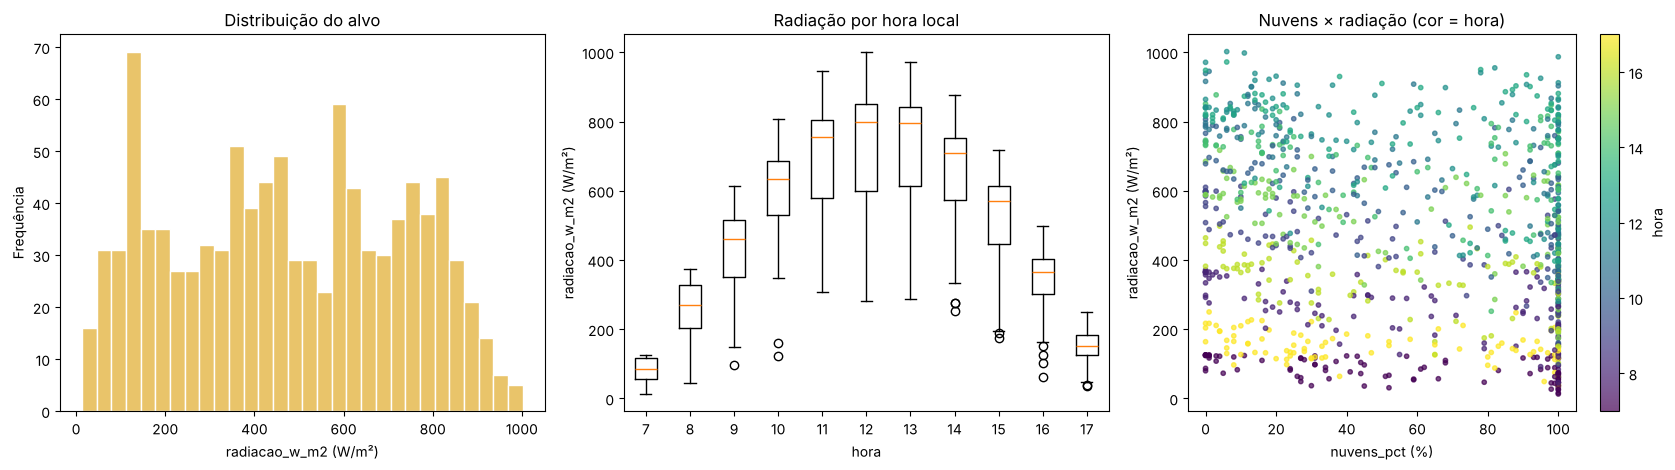

In [28]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8))

eixos[0].hist(meteo["radiacao_w_m2"], bins=30, color="#e9c46a", edgecolor="white")
eixos[0].set_title("Distribuição do alvo")
eixos[0].set_xlabel("radiacao_w_m2 (W/m²)")
eixos[0].set_ylabel("Frequência")

horas = sorted(meteo["hora"].unique())
eixos[1].boxplot([meteo.loc[meteo["hora"] == h, "radiacao_w_m2"] for h in horas], tick_labels=horas)
eixos[1].set_title("Radiação por hora local")
eixos[1].set_xlabel("hora")
eixos[1].set_ylabel("radiacao_w_m2 (W/m²)")

pontos = eixos[2].scatter(meteo["nuvens_pct"], meteo["radiacao_w_m2"], c=meteo["hora"],
                          cmap="viridis", s=10, alpha=0.7)
eixos[2].set_title("Nuvens × radiação (cor = hora)")
eixos[2].set_xlabel("nuvens_pct (%)")
eixos[2].set_ylabel("radiacao_w_m2 (W/m²)")
fig.colorbar(pontos, ax=eixos[2], label="hora")
plt.tight_layout()
plt.show()

In [29]:
ATRIBUTOS_REG = ["temperatura_c", "umidade_pct", "nuvens_pct", "vento_kmh", "hora"]
ALVO = "radiacao_w_m2"
meteo[ATRIBUTOS_REG + [ALVO]].corr()[ALVO].drop(ALVO).sort_values().to_frame("correlação de Pearson com o alvo").round(3)

,correlação de Pearson com o alvo
umidade_pct,-0.596
vento_kmh,-0.229
nuvens_pct,-0.180
hora,0.120
temperatura_c,0.643


**O que a exploração mostra**

- São **1.001 horas** (91 dias × 11 horas, das 7h às 17h) de **01/04/2025 a 30/06/2025**, em ordem cronológica, sem valores ausentes e sem horários repetidos. `data_hora` serve apenas para ordenar e dividir.
- O alvo `radiacao_w_m2` vai de 13 a 1.002 W/m² (média ≈ 473 W/m²).
- **Hora do dia:** o boxplot mostra uma curva em forma de "sino": a radiação é baixa às 7h e 17h e máxima entre 11h e 13h, acompanhando a altura do Sol. Por isso, a correlação de Pearson entre `hora` e o alvo é quase nula (0,12) — a relação é forte, mas **não linear** (sobe de manhã e desce à tarde).
- **Nuvens:** com a mesma hora, mais nuvens tendem a reduzir a radiação, mas a dispersão é grande (100% de cobertura ainda permite radiação alta, pois a cobertura total não informa a espessura das nuvens).
- **Temperatura (+0,64) e umidade (−0,60)** são as variáveis com maior correlação linear; em parte porque também seguem o ciclo diário (o ar esquenta e seca durante o dia), em parte porque dias claros são mais quentes e secos.

### 6. Definição de X e y e divisão temporal 80% / 20%

In [30]:
X_reg = meteo[ATRIBUTOS_REG]
y_reg = meteo[ALVO]

corte = int(len(meteo) * 0.8)
X_treino_reg, X_teste_reg = X_reg.iloc[:corte], X_reg.iloc[corte:]
y_treino_reg, y_teste_reg = y_reg.iloc[:corte], y_reg.iloc[corte:]
datas_teste = meteo["data_hora"].iloc[corte:]

print(f"Treino: {len(X_treino_reg)} horas | {meteo['data_hora'].iloc[0]} até {meteo['data_hora'].iloc[corte - 1]}")
print(f"Teste:  {len(X_teste_reg)} horas | {meteo['data_hora'].iloc[corte]} até {meteo['data_hora'].iloc[-1]}")
print("Entradas:", list(X_reg.columns))
print("Alvo:", ALVO)

Treino: 800 horas | 2025-04-01 07:00:00 até 2025-06-12 14:00:00
Teste:  201 horas | 2025-06-12 15:00:00 até 2025-06-30 17:00:00
Entradas: ['temperatura_c', 'umidade_pct', 'nuvens_pct', 'vento_kmh', 'hora']
Alvo: radiacao_w_m2


Os mesmos dois subconjuntos são exportados para a atividade no Orange (opção *Test on test data* em **Test & Score**), garantindo que a comparação com o Python use exatamente a mesma divisão.

In [31]:
meteo_orange = meteo.copy()
meteo_orange["data_hora"] = meteo_orange["data_hora"].dt.strftime("%Y-%m-%dT%H:%M")
meteo_orange.iloc[:corte].to_csv("meteo_treino_orange.csv", index=False, encoding="utf-8-sig")
meteo_orange.iloc[corte:].to_csv("meteo_teste_orange.csv", index=False, encoding="utf-8-sig")
print("Salvos: meteo_treino_orange.csv e meteo_teste_orange.csv")

Salvos: meteo_treino_orange.csv e meteo_teste_orange.csv


### Escolha dos três regressores

| Algoritmo | Por que foi escolhido | Configuração |
|---|---|---|
| **Regressão Linear** | Linha de base simples e interpretável; mostra o que se obtém supondo relações lineares. | Padrão do scikit-learn |
| **Árvore de Decisão** | Capta relações não lineares, como o formato de sino da radiação ao longo do dia, e regras do tipo "hora entre 10h e 14h **e** poucas nuvens". | `max_depth=6`, `min_samples_leaf=5` para limitar o sobreajuste |
| **Random Forest** | Média de muitas árvores treinadas em amostras diferentes; reduz a variância de uma árvore isolada. | 300 árvores, `min_samples_leaf=2` |

Os hiperparâmetros foram fixados antes da avaliação (não foram ajustados olhando o teste). Nenhum dos três modelos exige padronização, e `radiacao_w_m2` não entra em `X`.

In [32]:
regressores = {
    "Regressão Linear": LinearRegression(),
    "Árvore de Decisão": DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=SEMENTE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEMENTE),
}

### 7. Treinamento e comparação dos três regressores

Todos são treinados nas primeiras 80% das horas e avaliados nas 20% finais. Como referência (não é um dos três modelos), a última linha mostra o erro de prever simplesmente a **média do treino para cada hora do dia**.

In [33]:
previsoes_reg = {}
linhas = []
for nome, modelo in regressores.items():
    modelo.fit(X_treino_reg, y_treino_reg)
    previsao = modelo.predict(X_teste_reg)
    previsoes_reg[nome] = previsao
    mse = mean_squared_error(y_teste_reg, previsao)
    linhas.append({"Modelo": nome,
                   "MAE (W/m²)": mean_absolute_error(y_teste_reg, previsao),
                   "MSE ((W/m²)²)": mse,
                   "RMSE (W/m²)": np.sqrt(mse),
                   "R²": r2_score(y_teste_reg, previsao)})

media_por_hora = y_treino_reg.groupby(X_treino_reg["hora"]).mean()
referencia = X_teste_reg["hora"].map(media_por_hora)
mse_ref = mean_squared_error(y_teste_reg, referencia)
linhas.append({"Modelo": "Referência: média do treino por hora",
               "MAE (W/m²)": mean_absolute_error(y_teste_reg, referencia),
               "MSE ((W/m²)²)": mse_ref,
               "RMSE (W/m²)": np.sqrt(mse_ref),
               "R²": r2_score(y_teste_reg, referencia)})

resultados_reg = pd.DataFrame(linhas).set_index("Modelo")
resultados_reg.round(3)

,MAE (W/m²),MSE ((W/m²)²),RMSE (W/m²),R²
Modelo,,,,
Regressão Linear,145.205,30034.201,173.304,0.360
Árvore de Decisão,87.137,14005.882,118.346,0.701
Random Forest,67.190,7419.598,86.137,0.842
Referência: média do treino por hora,132.064,33469.355,182.946,0.287


Melhor regressor (menor MAE): Random Forest


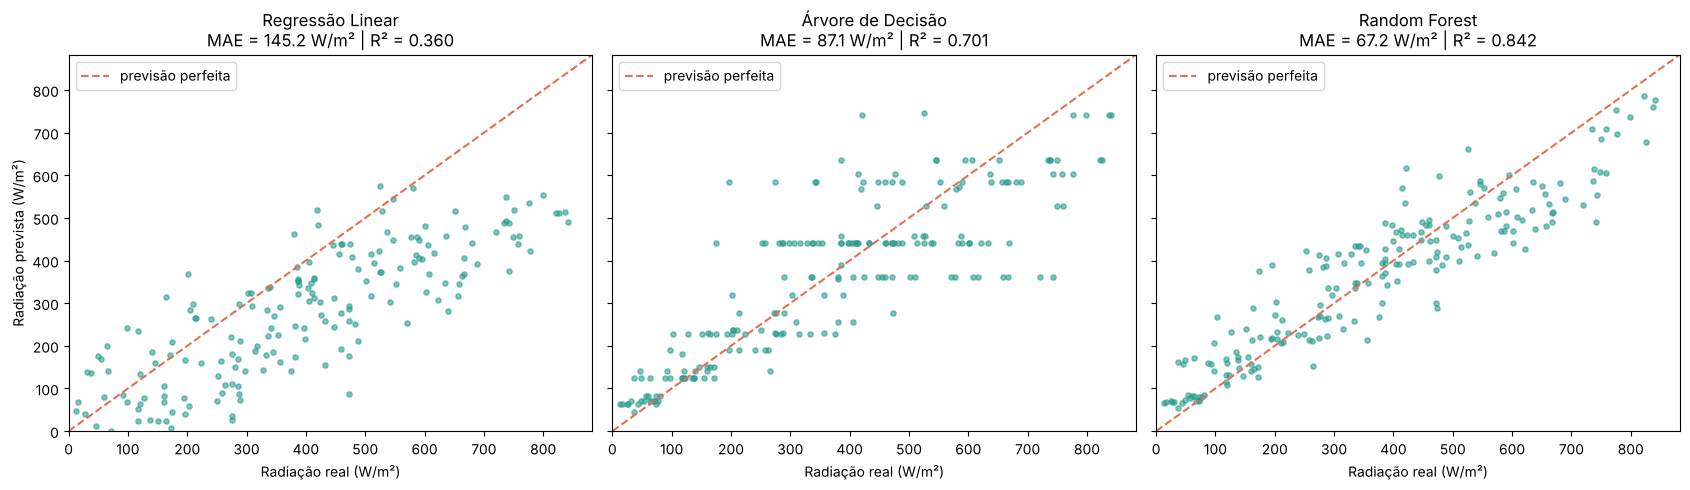

In [34]:
melhor_reg = resultados_reg.drop("Referência: média do treino por hora")["MAE (W/m²)"].idxmin()
print("Melhor regressor (menor MAE):", melhor_reg)

fig, eixos = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
limite = [0, max(y_teste_reg.max(), max(p.max() for p in previsoes_reg.values())) * 1.05]
for eixo, (nome, previsao) in zip(eixos, previsoes_reg.items()):
    eixo.scatter(y_teste_reg, previsao, s=14, alpha=0.6, color="#2a9d8f")
    eixo.plot(limite, limite, color="#e76f51", linestyle="--", label="previsão perfeita")
    eixo.set_title(f"{nome}\nMAE = {mean_absolute_error(y_teste_reg, previsao):.1f} W/m² | R² = {r2_score(y_teste_reg, previsao):.3f}")
    eixo.set_xlabel("Radiação real (W/m²)")
    eixo.set_xlim(limite)
    eixo.set_ylim(limite)
    eixo.legend(loc="upper left")
eixos[0].set_ylabel("Radiação prevista (W/m²)")
plt.tight_layout()
plt.show()

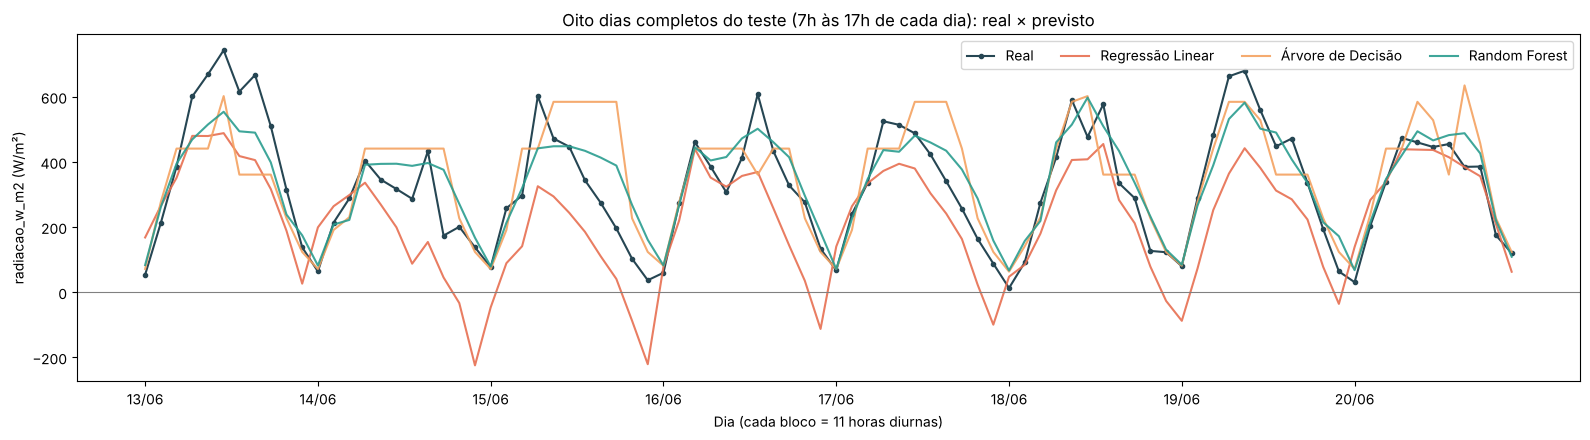

In [35]:
inicio = int(np.argmax(X_teste_reg["hora"].to_numpy() == 7))
janela = slice(inicio, inicio + 11 * 8)
eixo_x = np.arange(len(y_teste_reg))
plt.figure(figsize=(16, 4.5))
plt.plot(eixo_x[janela], y_teste_reg.to_numpy()[janela], marker="o", markersize=3,
         color="#264653", label="Real")
for nome, cor in zip(previsoes_reg, ["#e76f51", "#f4a261", "#2a9d8f"]):
    plt.plot(eixo_x[janela], previsoes_reg[nome][janela], color=cor, alpha=0.9, label=nome)
plt.axhline(0, color="gray", linewidth=0.8)
marcas = list(range(inicio, inicio + 11 * 8, 11))
plt.xticks(marcas, datas_teste.iloc[marcas].dt.strftime("%d/%m"), rotation=0)
plt.title("Oito dias completos do teste (7h às 17h de cada dia): real × previsto")
plt.ylabel("radiacao_w_m2 (W/m²)")
plt.xlabel("Dia (cada bloco = 11 horas diurnas)")
plt.legend(ncol=4)
plt.tight_layout()
plt.show()

In [36]:
erros_por_hora = pd.DataFrame({nome: np.abs(y_teste_reg.to_numpy() - previsao)
                               for nome, previsao in previsoes_reg.items()})
erros_por_hora["hora"] = X_teste_reg["hora"].to_numpy()
erros_por_hora.groupby("hora").mean().round(1).rename(columns=lambda nome: f"MAE {nome}")

,MAE Regressão Linear,MAE Árvore de Decisão,MAE Random Forest
hora,,,
7,99.6,20.3,22.6
8,107.1,39.5,33.5
9,125.8,73.4,69.0
10,181.7,92.4,93.7
11,178.3,119.0,83.7
12,163.6,101.6,76.0
13,188.6,175.5,86.6
14,160.3,132.7,89.6
15,132.5,116.2,82.2


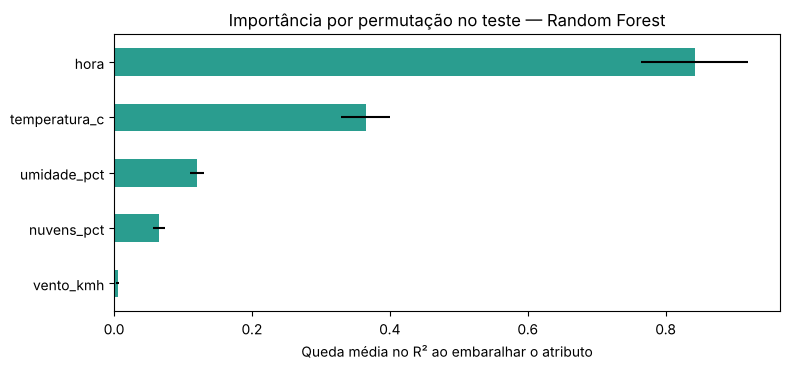

,queda média no R²,desvio
hora,0.842,0.078
temperatura_c,0.365,0.035
umidade_pct,0.120,0.011
nuvens_pct,0.065,0.008
vento_kmh,0.005,0.002


In [37]:
importancia = permutation_importance(regressores[melhor_reg], X_teste_reg, y_teste_reg,
                                     n_repeats=20, random_state=SEMENTE, scoring="r2")
tabela_importancia = pd.DataFrame({"queda média no R²": importancia.importances_mean,
                                   "desvio": importancia.importances_std},
                                  index=ATRIBUTOS_REG).sort_values("queda média no R²", ascending=False)

tabela_importancia["queda média no R²"].plot.barh(figsize=(8, 3.8), color="#2a9d8f",
                                                  xerr=tabela_importancia["desvio"])
plt.gca().invert_yaxis()
plt.title(f"Importância por permutação no teste — {melhor_reg}")
plt.xlabel("Queda média no R² ao embaralhar o atributo")
plt.tight_layout()
plt.show()
tabela_importancia.round(3)

### 8. Interpretação — regressão

**Tabela comparativa (teste = últimas 201 horas, de 12/06 15h a 30/06 17h):**

| Modelo | MAE (W/m²) | MSE ((W/m²)²) | R² |
|---|---|---|---|
| Random Forest | 67,2 | 7.419,6 | 0,842 |
| Árvore de Decisão | 87,1 | 14.005,9 | 0,701 |
| Regressão Linear | 145,2 | 30.034,2 | 0,360 |

- **Modelo escolhido: Random Forest**, com o menor MAE (erro médio de ~67 W/m²), o menor MSE e o maior R² (explica ~84% da variação da radiação no período de teste). A Árvore de Decisão vem em segundo; no gráfico temporal ela produz previsões "em degraus", porque cada folha devolve um valor constante. A Regressão Linear é a pior e chega a prever **radiação negativa**, o que é fisicamente impossível.
- **Erros:** os maiores erros aparecem perto do meio-dia (10h–15h), quando a radiação é maior e mais sensível à passagem de nuvens; nas pontas do dia (7h e 17h) o erro é pequeno porque a radiação é sempre baixa. O MSE pune muito os erros grandes, por isso a diferença entre os modelos é maior no MSE do que no MAE.
- **Mudança de estação:** o teste corresponde à segunda quinzena de junho, perto do solstício de inverno, quando a radiação média é menor (≈ 373 W/m² no teste contra ≈ 498 W/m² no treino). Como a divisão é temporal, os modelos precisam extrapolar para um período um pouco diferente — situação realista, que a validação aleatória esconderia.

**Papel da hora do dia**

A hora é o atributo **mais importante** para o Random Forest: embaralhar a coluna `hora` derruba o R² em ~0,84, muito mais do que qualquer variável meteorológica. Ela representa a **posição do Sol**, que define o limite máximo de radiação possível em cada momento; as nuvens, a umidade e a temperatura explicam quanto desse limite chega ao solo. Como a relação é em forma de sino, a Regressão Linear não consegue aproveitá-la (o coeficiente da hora só representa um aumento ou uma queda constante ao longo do dia), enquanto os modelos de árvore a usam bem. A referência "média do treino por hora" (R² = 0,29) mostra que a hora sozinha não basta: as condições do tempo e a estação do ano também importam.

**Por que radiação não é geração elétrica**

O modelo estima a **radiação solar global horizontal** (W/m², potência por área que chega a uma superfície plana), derivada de modelos/reanálise e não medida em um painel. A **energia gerada** (kWh) por um sistema fotovoltaico depende também de: área e potência instalada dos módulos, eficiência dos painéis e do inversor, inclinação e orientação (a radiação no plano do módulo é diferente da horizontal), temperatura das células (o calor reduz a eficiência), sombreamento, sujeira, perdas em cabos e limitações da rede. Além disso, W/m² é potência média, e energia exige integrar no tempo. Assim, a radiação é uma **entrada** para estimar a geração, mas não a substitui.

# Conclusões gerais

| Tarefa | Avaliação | Algoritmos comparados | Melhor modelo | Resultado no teste |
|---|---|---|---|---|
| Classificação da fonte (ANEEL) | Holdout estratificado 80/20, `random_state=42`; métricas com média `macro` | Regressão Logística, kNN (k = 5), Random Forest | **Random Forest** | Accuracy 0,977; F1 macro 0,977 |
| Regressão da radiação (Open-Meteo) | Divisão temporal: primeiras 80% das horas para treino, últimas 20% para teste | Regressão Linear, Árvore de Decisão, Random Forest | **Random Forest** | MAE 67,2 W/m²; MSE 7.419,6 (W/m²)²; R² 0,842 |

- Nas duas tarefas, os modelos baseados em árvores superaram os lineares, porque as relações entre entradas e alvo são não lineares (aglomerados geográficos e faixas de potência na classificação; ciclo diário em forma de sino na regressão).
- Os números devem ser lidos com as limitações discutidas: na classificação, a amostra é limitada e há empreendimentos vizinhos do mesmo complexo no treino e no teste; na regressão, os dados são estimados para um único ponto e três meses, e a radiação não equivale à energia gerada.
- Os dados da ANEEL são atualizados com frequência. Se o notebook for executado em outra data, a consulta pode retornar registros diferentes e os valores podem variar um pouco em relação aos registrados aqui.

# Entrega pelo GitHub

Envie **apenas o link do repositório público**. Organize-o com:

- `README.md` contendo objetivo, fontes e período dos dados, instruções para executar o notebook e resumo dos resultados;
- notebook `.ipynb` com a consulta às APIs, sua análise, os **três classificadores e os três regressores**, todos os imports necessários adicionados por você e conclusões em Markdown;
- os dois CSVs gerados (ou instruções completas e testadas para reproduzi-los) e eventuais figuras utilizadas.

Verifique se o notebook roda **na ordem das células** a partir de um ambiente limpo. Não inclua senhas, tokens ou arquivos sem relação com a avaliação. A banca deve conseguir encontrar as seis comparações e as respostas às duas tarefas sem procurar uma agulha no palheiro.

### Fontes

- [ANEEL — SIGA](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel)
- [ANEEL — recurso e campos usados](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel/resource/11ec447d-698d-4ab8-977f-b424d5deee6a)
- [Open-Meteo — histórico e unidades](https://open-meteo.com/en/docs/historical-weather-api)